# Customer Churn Baseline Model

This notebook reproduces the baseline workflow for RabTech Academy Task 02: **ML Problem Framing & Responsible Data Card**.

The supplied dataset contains only 12 records. This is an educational baseline: metrics are unstable and must not be interpreted as production performance. Predictions require human review and responsible-use safeguards.

## 1. Import libraries

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    brier_score_loss,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

## 2. Load the existing dataset

In [2]:
DATA_FILE = Path.cwd() / "customer-churn-training.csv"
TARGET = "churned"
ID_COLUMN = "customer_id"

if not DATA_FILE.exists():
    raise FileNotFoundError(f"Could not find {DATA_FILE.name} in {Path.cwd()}")

data = pd.read_csv(DATA_FILE)
data

,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0
5,C006,1,5,499,30,Basic,1
6,C007,24,1,999,3,Standard,0
7,C008,8,4,799,17,Basic,1
8,C009,15,2,1299,4,Pro,0
9,C010,4,3,499,12,Basic,1


## 3. Dataset shape and column names

In [3]:
print(f"Dataset shape: {data.shape}")
print(f"Column names: {list(data.columns)}")

Dataset shape: (12, 7)
Column names: ['customer_id', 'tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type', 'churned']


## 4. First few rows

In [4]:
data.head()

,customer_id,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,churned
0,C001,2,4,499,21,Basic,1
1,C002,18,1,1299,2,Pro,0
2,C003,6,3,799,14,Basic,1
3,C004,30,0,1499,1,Pro,0
4,C005,11,2,999,5,Standard,0


## 5. Missing values

In [5]:
data.isna().sum()

customer_id          0
tenure_months        0
support_tickets      0
monthly_spend_inr    0
last_login_days      0
plan_type            0
churned              0
dtype: int64

## 6. Duplicate rows

In [6]:
print(f"Duplicate rows: {data.duplicated().sum()}")

Duplicate rows: 0


## 7. Data types

In [7]:
data.dtypes

customer_id            str
tenure_months        int64
support_tickets      int64
monthly_spend_inr    int64
last_login_days      int64
plan_type              str
churned              int64
dtype: object

## 8. Descriptive statistics

In [8]:
data.select_dtypes(include="number").describe()

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,churned
count,12.000000,12.000000,12.000000,12.000000,12.000000
mean,12.166667,2.250000,915.666667,10.000000,0.416667
std,9.242524,1.602555,332.574895,9.095453,0.514929
min,1.000000,0.000000,499.000000,1.000000,0.000000
25%,5.500000,1.000000,724.000000,2.750000,0.000000
50%,9.500000,2.000000,899.000000,7.000000,0.000000
75%,18.500000,3.250000,1074.000000,14.750000,1.000000
max,30.000000,5.000000,1499.000000,30.000000,1.000000


## 9. Churn target distribution and percentages

In [9]:
target_counts = data[TARGET].value_counts().sort_index()
print("Churned target distribution (0=non-churn, 1=churn):")
print(target_counts)
print("Churn percentage: {:.1f}%".format(data[TARGET].mean() * 100))
print("Non-churn percentage: {:.1f}%".format((1 - data[TARGET].mean()) * 100))

Churned target distribution (0=non-churn, 1=churn):
churned
0    7
1    5
Name: count, dtype: int64
Churn percentage: 41.7%
Non-churn percentage: 58.3%


## 10. Feature identification

In [10]:
feature_columns = [column for column in data.columns if column not in {TARGET, ID_COLUMN}]
categorical_features = data[feature_columns].select_dtypes(
    include=["str", "category", "bool"]
).columns.tolist()
numerical_features = data[feature_columns].select_dtypes(
    include="number"
).columns.tolist()
print(f"Categorical features: {categorical_features}")
print(f"Numerical features: {numerical_features}")

Categorical features: ['plan_type']
Numerical features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days']


## 11. Exclude the identifier and target from model features

In [11]:
X = data[feature_columns]
y = data[TARGET]
print(f"Model features: {list(X.columns)}")
print(f"customer_id excluded from X: {ID_COLUMN not in X.columns}")
print(f"churned excluded from X: {TARGET not in X.columns}")

Model features: ['tenure_months', 'support_tickets', 'monthly_spend_inr', 'last_login_days', 'plan_type']
customer_id excluded from X: True
churned excluded from X: True


## 12. Target leakage check

In [12]:
leakage_candidates = [
    column
    for column in feature_columns
    if "churn" in column.lower() or "target" in column.lower()
]
print(f"Name-based leakage candidates requiring review: {leakage_candidates or 'None detected'}")
print("The target and customer_id are excluded before model construction.")

Name-based leakage candidates requiring review: None detected
The target and customer_id are excluded before model construction.


## 13. Same train/test split as the Python baseline

In [13]:
if y.nunique() < 2:
    raise ValueError("At least two target classes are required for this comparison.")
if y.value_counts().min() < 2:
    raise ValueError("Each target class needs at least two records for a safe split.")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"Training rows: {len(X_train)}; testing rows: {len(X_test)}")
print(y_test.value_counts().sort_index())

Training rows: 9; testing rows: 3
churned
0    2
1    1
Name: count, dtype: int64


## 14. Shared metric and confusion-matrix reporting

In [14]:
def print_metrics(name, y_true, predictions, probabilities=None):
    print(f"\n{name} metrics")
    print(f"Accuracy:  {accuracy_score(y_true, predictions):.3f}")
    print(f"Precision: {precision_score(y_true, predictions, zero_division=0):.3f}")
    print(f"Recall:    {recall_score(y_true, predictions, zero_division=0):.3f}")
    print(f"F1-score:  {f1_score(y_true, predictions, zero_division=0):.3f}")
    print("Classification report:")
    print(classification_report(y_true, predictions, zero_division=0))
    print("Confusion matrix (rows=true, columns=predicted; labels 0, 1):")
    print(confusion_matrix(y_true, predictions, labels=[0, 1]))
    if probabilities is None:
        print("Calibration: unavailable because this model does not provide probabilities.")
    else:
        print(f"Brier score: {brier_score_loss(y_true, probabilities):.3f}")
        print("Calibration warning: this estimate is unreliable with only the small test set in this dataset.")

## 15. Majority-class non-ML baseline

In [15]:
majority_model = DummyClassifier(strategy="most_frequent")
majority_model.fit(X_train, y_train)
majority_predictions = majority_model.predict(X_test)
print_metrics("Majority-class non-ML baseline", y_test, majority_predictions)


Majority-class non-ML baseline metrics
Accuracy:  0.667
Precision: 0.000
Recall:    0.000
F1-score:  0.000
Classification report:
              precision    recall  f1-score   support

           0       0.67      1.00      0.80         2
           1       0.00      0.00      0.00         1

    accuracy                           0.67         3
   macro avg       0.33      0.50      0.40         3
weighted avg       0.44      0.67      0.53         3

Confusion matrix (rows=true, columns=predicted; labels 0, 1):
[[2 0]
 [1 0]]
Calibration: unavailable because this model does not provide probabilities.


## 16. Logistic Regression baseline

In [16]:
transformers = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numerical_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)
logistic_model = Pipeline(
    steps=[
        ("preprocess", transformers),
        ("model", LogisticRegression(max_iter=1000, random_state=42)),
    ]
)
logistic_model.fit(X_train, y_train)
logistic_predictions = logistic_model.predict(X_test)
logistic_probabilities = logistic_model.predict_proba(X_test)[:, 1]

## 17. Logistic Regression metrics and calibration

In [17]:
print_metrics(
    "Logistic Regression baseline",
    y_test,
    logistic_predictions,
    logistic_probabilities,
)


Logistic Regression baseline metrics
Accuracy:  1.000
Precision: 1.000
Recall:    1.000
F1-score:  1.000
Classification report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         1

    accuracy                           1.00         3
   macro avg       1.00      1.00      1.00         3
weighted avg       1.00      1.00      1.00         3

Confusion matrix (rows=true, columns=predicted; labels 0, 1):
[[2 0]
 [0 1]]
Brier score: 0.065
Calibration warning: this estimate is unreliable with only the small test set in this dataset.


## 18. Confusion-matrix visualization

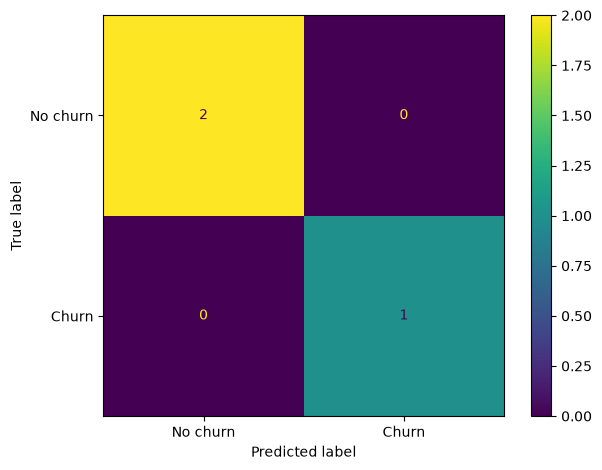

In [18]:
ConfusionMatrixDisplay.from_predictions(
    y_test, logistic_predictions, labels=[0, 1], display_labels=["No churn", "Churn"]
)
plt.tight_layout()
plt.show()

## 19. Simple Logistic Regression error analysis

In [19]:
error_table = X_test.copy()
error_table["actual_churned"] = y_test
error_table["predicted_churned"] = logistic_predictions
error_table["error"] = error_table["actual_churned"] != error_table["predicted_churned"]
display(error_table[error_table["error"]])
print(f"Total test errors: {int(error_table['error'].sum())} of {len(error_table)}")

,tenure_months,support_tickets,monthly_spend_inr,last_login_days,plan_type,actual_churned,predicted_churned,error


Total test errors: 0 of 3


## 20. Errors by `plan_type` and fairness limitation

In [20]:
if "plan_type" in data.columns:
    print("Errors by plan_type (descriptive only):")
    display(
        error_table.groupby("plan_type", observed=True)
        .agg(records=("error", "size"), errors=("error", "sum"))
    )
    print("Warning: group-level fairness comparisons are unreliable with so few records, especially for small plan_type groups.")

Errors by plan_type (descriptive only):


,records,errors
plan_type,,
Basic,1,0
Standard,2,0


## 21. Final limitations and responsible use

- The majority baseline always predicts the most common training class and provides a simple reference point for evaluating Logistic Regression.
- The Logistic Regression baseline combines the available numeric features with one-hot encoded `plan_type`; it is an educational comparison, not evidence of production benefit.
- A false positive predicts churn when the customer does not churn and may lead to an unnecessary retention contact. A false negative misses a customer who churns and may miss an opportunity for human review.
- The test set contains very few records, so accuracy, precision, recall, F1-score, confusion-matrix counts, and the Brier score are unstable.
- Fairness comparisons are unreliable because the dataset has only 12 records and no protected-group fields. Calibration is also unreliable with this small test set.
- Predictions must support, not automatically determine, customer-retention actions. Human review is required, and the model must not be used for automatic adverse decisions or unrelated customer decisions.